CUSTOMER SEGMENTATION ANALYSIS

1. INSTALL DEPENDENCIES

In [ ]:
%pip install -U "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

2. IMPORT LIBRARIES

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from kagglehub import KaggleDatasetAdapter
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

3. LOAD DATASET DIRECTLY FROM KAGGLE

In [20]:
# Dataset file
file_path = "data.csv"

# Load dataset using the correct encoding
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "carrie1/ecommerce-data",
    file_path,
    pandas_kwargs={
        "encoding": "ISO-8859-1"
    }
)

print("Dataset loaded successfully!")

print("\nFirst 5 records:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())


Using Colab cache for faster access to the 'ecommerce-data' dataset.
Dataset loaded successfully!

First 5 records:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Dataset shape:
(541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 

4. DATA CLEANING

In [21]:
data = df.copy()

# Standardize column names
data.columns = data.columns.str.strip()

required_columns = [
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "CustomerID"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("\nOriginal rows:", len(data))

# A: Remove duplicate records
duplicates = data.duplicated().sum()

data = data.drop_duplicates().copy()

print("Duplicate rows removed:", duplicates)

# B: Convert invoice date to datetime
data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"],
    errors="coerce"
)

# C: Convert numerical columns
data["Quantity"] = pd.to_numeric(
    data["Quantity"],
    errors="coerce"
)

data["UnitPrice"] = pd.to_numeric(
    data["UnitPrice"],
    errors="coerce"
)

data["CustomerID"] = pd.to_numeric(
    data["CustomerID"],
    errors="coerce"
)

# D: Remove rows without essential information
before = len(data)

data = data.dropna(
    subset=[
        "CustomerID",
        "InvoiceNo",
        "InvoiceDate",
        "Quantity",
        "UnitPrice"
    ]
).copy()

print(
    "Rows removed due to missing essential values:",
    before - len(data)
)

# E: CustomerID should be a category/identifier,
# not a numeric measurement.
data["CustomerID"] = (
    data["CustomerID"].astype("int64").astype(str)
)

# F: Standardize invoice numbers
data["InvoiceNo"] = (
    data["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# G: Remove cancelled transactions
# Invoice numbers beginning with 'C' indicate cancellation.
cancelled = data["InvoiceNo"].str.startswith("C")

print(
    "Cancelled transaction lines removed:",
    cancelled.sum()
)

data = data.loc[~cancelled].copy()

# H: Exclude returns, zero quantities, and
# non-positive unit prices from purchase analysis.
invalid_values = (
    (data["Quantity"] <= 0) |
    (data["UnitPrice"] <= 0)
)

print(
    "Invalid quantity/price rows removed:",
    invalid_values.sum()
)

data = data.loc[~invalid_values].copy()

# I: Standardize other text columns where present
for col in ["Description", "Country", "StockCode"]:
    if col in data.columns:
        data[col] = (
            data[col]
            .astype("string")
            .str.strip()
        )

# J: Calculate line revenue
data["TotalPrice"] = (
    data["Quantity"] * data["UnitPrice"]
)

# Remove unexpected non-finite results
data = data.loc[
    np.isfinite(data["TotalPrice"])
].copy()

print("\nCleaned dataset shape:", data.shape)

print("\nMissing values after cleaning:")
print(data.isnull().sum())

print("\nUnique customers:", data["CustomerID"].nunique())

print("\nUnique invoices:", data["InvoiceNo"].nunique())

print("\nDate range:")
print(
    data["InvoiceDate"].min(),
    "to",
    data["InvoiceDate"].max()
)

if data.empty:
    raise ValueError("No valid purchase records remain.")

# NOTE:
# We analyse completed positive purchases.
# Revenue excludes returns/cancellations.
# Therefore, customer spending is gross positive
# purchase revenue, not net of refunds.


Original rows: 541909
Duplicate rows removed: 5268
Rows removed due to missing essential values: 135037
Cancelled transaction lines removed: 8872
Invalid quantity/price rows removed: 40

Cleaned dataset shape: (392692, 9)

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Unique customers: 4338

Unique invoices: 18532

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


5. DESCRIPTIVE STATISTICS

In [22]:
print("\nGENERAL SALES STATISTICS")
print("=" * 50)

print(
    "Total observed sales:",
    round(data["TotalPrice"].sum(), 2)
)

print(
    "Total customers:",
    data["CustomerID"].nunique()
)

print(
    "Total purchase invoices:",
    data["InvoiceNo"].nunique()
)

# Aggregate item rows into complete purchase invoices
# Use CustomerID + InvoiceNo so invoice counts
# are correctly associated with each customer.

orders = (
    data.groupby(
        ["CustomerID", "InvoiceNo"],
        as_index=False
    )
    .agg(
        OrderDate=("InvoiceDate", "max"),
        OrderValue=("TotalPrice", "sum")
    )
)

print(
    "\nAverage Purchase Value (overall):",
    round(orders["OrderValue"].mean(), 2)
)



GENERAL SALES STATISTICS
Total observed sales: 8887208.89
Total customers: 4338
Total purchase invoices: 18532

Average Purchase Value (overall): 479.56


6. CUSTOMER METRICS + RFM ANALYSIS

In [23]:
# Snapshot one day after the most recent purchase.
# This avoids relying on today's date for historical data.

snapshot_date = (
    data["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

customer_metrics = (
    orders.groupby("CustomerID")
    .agg(
        FirstPurchase=("OrderDate", "min"),
        LastPurchase=("OrderDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("OrderValue", "sum"),
        AveragePurchaseValue=("OrderValue", "mean")
    )
    .reset_index()
)

# Recency: days since last purchase.
# Smaller recency means more recent activity.
customer_metrics["Recency"] = (
    snapshot_date
    - customer_metrics["LastPurchase"]
).dt.total_seconds() / 86400

# Observation window measured from source dataset
observation_days = max(
    (
        data["InvoiceDate"].max()
        - data["InvoiceDate"].min()
    ).total_seconds() / 86400,
    1
)

observation_months = observation_days / 30.44

# Average number of invoices per observation month
customer_metrics["MonthlyPurchaseFrequency"] = (
    customer_metrics["Frequency"] / observation_months
)

# Historical CLV proxy (NOT future predicted CLV).
# Since we're using positive purchase invoices:
# sum of observed order values = APV * Frequency.
customer_metrics["ObservedCLVProxy"] = (
    customer_metrics["AveragePurchaseValue"]
    * customer_metrics["Frequency"]
)

# More meaningful monetary values are already contained
# in the RFM metric "Monetary".
# Avoid misleading interpretation as predictive CLV.

rfm = customer_metrics[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "AveragePurchaseValue",
        "MonthlyPurchaseFrequency",
        "ObservedCLVProxy"
    ]
].copy()

print("\nCUSTOMER PURCHASE STATISTICS")
print("=" * 50)

print(
    "Average purchase value:",
    round(orders["OrderValue"].mean(), 2)
)

print(
    "Mean invoices per customer:",
    round(rfm["Frequency"].mean(), 2)
)

print(
    "Average monthly invoice frequency:",
    round(
        rfm["MonthlyPurchaseFrequency"].mean(),
        3
    )
)

print(
    "Mean observed customer revenue:",
    round(rfm["ObservedCLVProxy"].mean(), 2)
)

print(
    "\nRFM statistics:"
)
print(
    rfm[
        ["Recency", "Frequency", "Monetary"]
    ].describe().round(2)
)

print("\nFirst 10 customer records:")
print(rfm.head(10))



CUSTOMER PURCHASE STATISTICS
Average purchase value: 479.56
Mean invoices per customer: 4.27
Average monthly invoice frequency: 0.348
Mean observed customer revenue: 2048.69

RFM statistics:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     93.05       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.07       1.00     306.48
50%      51.09       2.00     668.57
75%     142.73       5.00    1660.60
max     374.12     209.00  280206.02

First 10 customer records:
  CustomerID     Recency  Frequency  Monetary  AveragePurchaseValue  \
0      12346  326.117361          1  77183.60          77183.600000   
1      12347    2.873611          7   4310.00            615.714286   
2      12348   75.984028          4   1797.24            449.310000   
3      12349   19.124306          1   1757.55           1757.550000   
4      12350  310.867361          1    334.40            334.400000   
5      12352   36.925

7. RFM EXPLORATORY VISUALIZATIONS

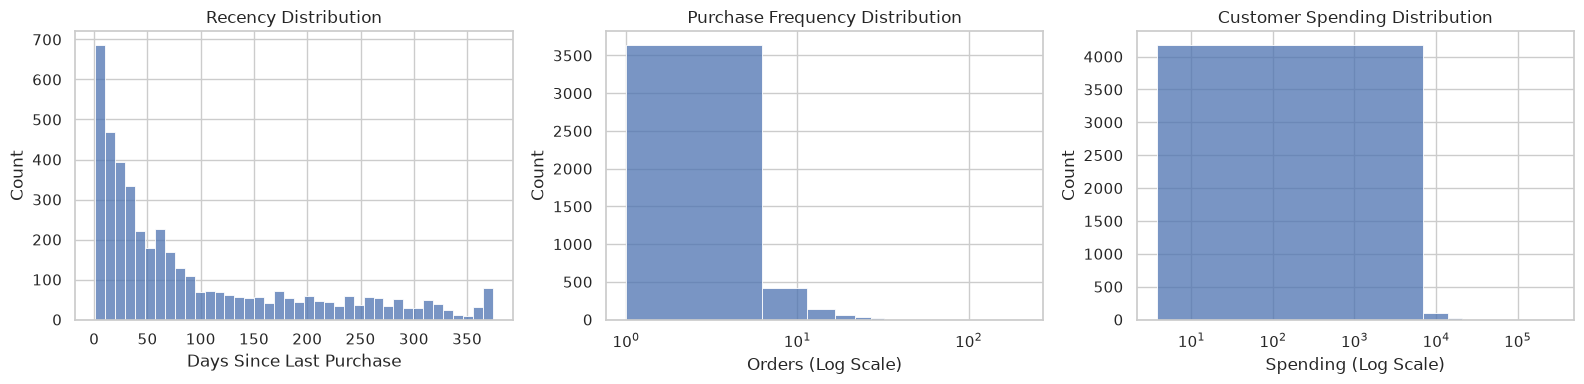

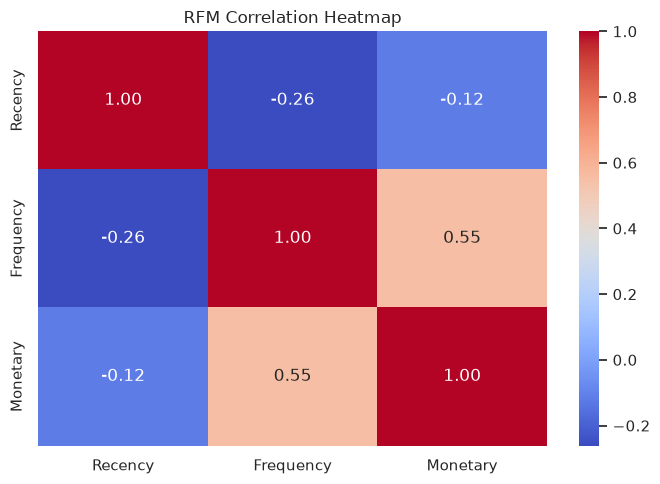

In [24]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

sns.histplot(
    rfm["Recency"],
    bins=40,
    ax=axes[0]
)

axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")

sns.histplot(
    rfm["Frequency"],
    bins=40,
    ax=axes[1]
)

axes[1].set_xscale("log")
axes[1].set_title("Purchase Frequency Distribution")
axes[1].set_xlabel("Orders (Log Scale)")

sns.histplot(
    rfm["Monetary"],
    bins=40,
    ax=axes[2]
)

axes[2].set_xscale("log")
axes[2].set_title("Customer Spending Distribution")
axes[2].set_xlabel("Spending (Log Scale)")

plt.tight_layout()
plt.show()

# RFM correlation heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm[
        ["Recency", "Frequency", "Monetary"]
    ].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("RFM Correlation Heatmap")
plt.tight_layout()
plt.show()

8. SELECT BEHAVIORAL FEATURES

In [25]:
# All three RFM variables are selected:
# Recency: How recently a customer purchased.
# Frequency: How often a customer purchased.
# Monetary: How much they spent.

features = [
    "Recency",
    "Frequency",
    "Monetary"
]

X_rfm = rfm[features].copy()

# Highly skewed spending and frequency can dominate
# distance-based clustering.
# log1p reduces skewness while preserving order.

X_transformed = np.log1p(X_rfm)

print("\nTransformed RFM values:")
print(X_transformed.head())


Transformed RFM values:
    Recency  Frequency   Monetary
0  5.790319   0.693147  11.253955
1  1.354187   2.079442   8.368925
2  4.343598   1.609438   7.494564
3  3.001928   0.693147   7.472245
4  5.742578   0.693147   5.815324


9. STANDARDIZATION USING STANDARDSCALER

In [26]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_transformed
)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=[
        "Recency_Scaled",
        "Frequency_Scaled",
        "Monetary_Scaled"
    ],
    index=rfm.index
)

print("\nScaled features:")
print(X_scaled_df.head())

print("\nScaled feature means:")
print(X_scaled_df.mean().round(5))

print("\nScaled feature standard deviations:")
print(
    X_scaled_df.std(ddof=0).round(5)
)



Scaled features:
   Recency_Scaled  Frequency_Scaled  Monetary_Scaled
0        1.479135         -0.955214         3.707716
1       -1.914481          1.074425         1.414903
2        0.372401          0.386304         0.720024
3       -0.653968         -0.955214         0.702287
4        1.442613         -0.955214        -0.614514

Scaled feature means:
Recency_Scaled     -0.0
Frequency_Scaled   -0.0
Monetary_Scaled    -0.0
dtype: float64

Scaled feature standard deviations:
Recency_Scaled      1.0
Frequency_Scaled    1.0
Monetary_Scaled     1.0
dtype: float64


10. ELBOW METHOD FOR OPTIMAL K

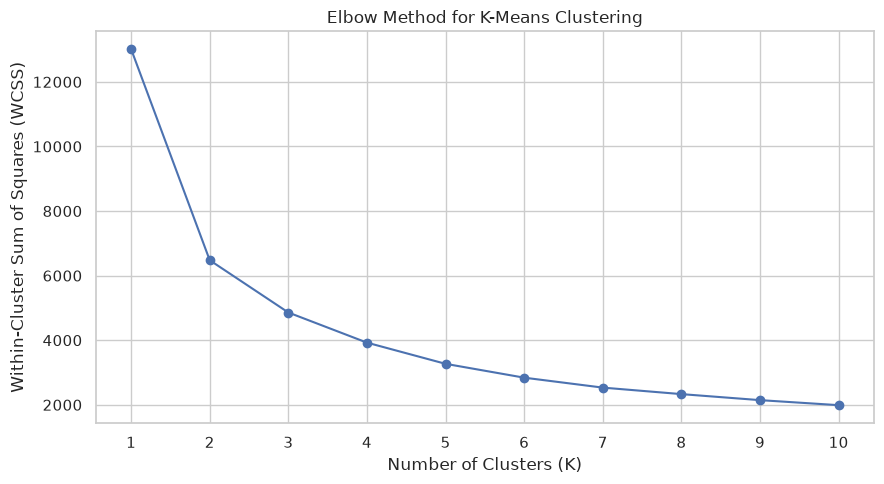


ELBOW METHOD RESULTS
    K      WCSS
0   1  13014.00
1   2   6476.80
2   3   4858.46
3   4   3925.52
4   5   3269.18
5   6   2840.62
6   7   2532.82
7   8   2331.37
8   9   2144.86
9  10   1989.19

Automatic elbow estimate: 3
Inspect the elbow chart and cluster profiles. You may override K if the elbow is ambiguous.


In [27]:
# Use K values from 1 to 10, or fewer if the
# dataset has fewer than 10 customers.

max_k = min(10, len(rfm))

if max_k < 3:
    raise ValueError(
        "At least 3 customers are needed for "
        "meaningful clustering."
    )

k_values = list(range(1, max_k + 1))
inertia_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(k_values)

plt.tight_layout()
plt.show()

print("\nELBOW METHOD RESULTS")

elbow_table = pd.DataFrame({
    "K": k_values,
    "WCSS": inertia_values
})

print(elbow_table.round(2))

# Automatic elbow estimate using the maximum distance
# from the straight line joining first and last points.
# This is a heuristic, not a guaranteed correct K.

p1 = np.array([
    k_values[0],
    inertia_values[0]
], dtype=float)

p2 = np.array([
    k_values[-1],
    inertia_values[-1]
], dtype=float)

# Normalize both axes to [0,1]
k_norm = (
    (np.array(k_values) - k_values[0])
    / (k_values[-1] - k_values[0])
)

inertia_arr = np.array(inertia_values)

denom = inertia_arr.max() - inertia_arr.min()

if denom == 0:
    inertia_norm = np.zeros_like(inertia_arr)
else:
    inertia_norm = (
        inertia_arr - inertia_arr.min()
    ) / denom

# Distance from diagonal
distances = np.abs(
    inertia_norm + k_norm - 1
) / np.sqrt(2)

# Select an interior K with at least 2 clusters.
candidate_indices = [
    i for i, k in enumerate(k_values)
    if 2 <= k < max_k
]

optimal_index = max(
    candidate_indices,
    key=lambda i: distances[i]
)

optimal_k = k_values[optimal_index]

print(
    "\nAutomatic elbow estimate:",
    optimal_k
)

print(
    "Inspect the elbow chart and cluster profiles. "
    "You may override K if the elbow is ambiguous."
)


11. K-MEANS CLUSTERING

In [28]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=20
)

rfm["Cluster"] = kmeans.fit_predict(
    X_scaled
)

print("\nClustering completed!")

print("\nFirst 10 clustered customers:")
print(rfm.head(10))

print("\nNumber of customers in each cluster:")
print(
    rfm["Cluster"].value_counts().sort_index()
)

# Silhouette Score: supporting cluster-quality metric
# Sample to make it computationally manageable.

silhouette_n = min(2000, len(rfm))

if (
    2 <= optimal_k
    < silhouette_n
):

    silhouette = silhouette_score(
        X_scaled,
        rfm["Cluster"],
        sample_size=silhouette_n,
        random_state=RANDOM_STATE
    )

    print(
        "\nSilhouette Score:",
        round(silhouette, 4)
    )


Clustering completed!

First 10 clustered customers:
  CustomerID     Recency  Frequency  Monetary  AveragePurchaseValue  \
0      12346  326.117361          1  77183.60          77183.600000   
1      12347    2.873611          7   4310.00            615.714286   
2      12348   75.984028          4   1797.24            449.310000   
3      12349   19.124306          1   1757.55           1757.550000   
4      12350  310.867361          1    334.40            334.400000   
5      12352   36.925694          8   2506.04            313.255000   
6      12353  204.793750          1     89.00             89.000000   
7      12354  232.985417          1   1079.40           1079.400000   
8      12355  214.959028          1    459.40            459.400000   
9      12356   23.173611          3   2811.43            937.143333   

   MonthlyPurchaseFrequency  ObservedCLVProxy  Cluster  
0                  0.081568          77183.60        0  
1                  0.570979           4310.00     

12. CLUSTER SCATTERPLOTS

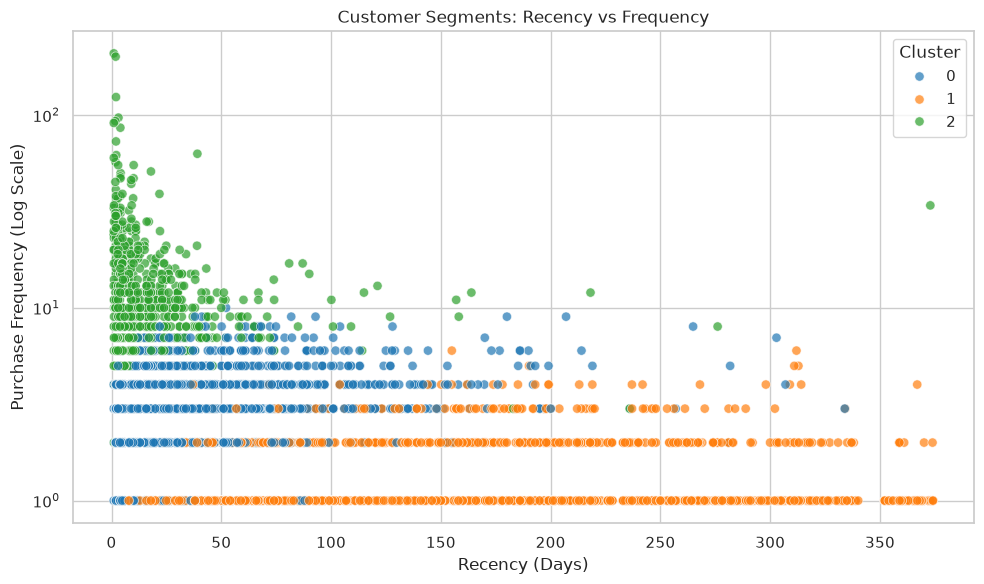

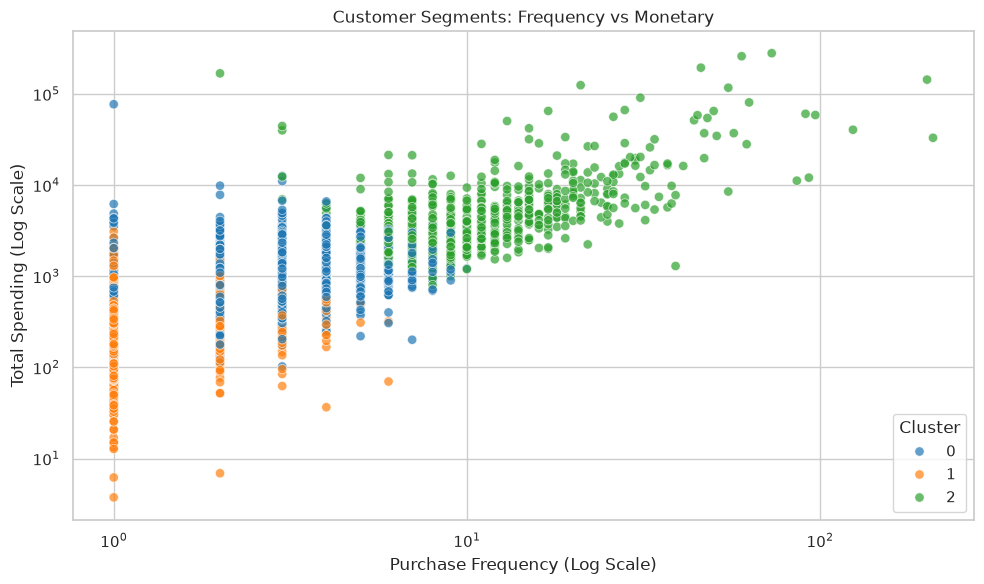

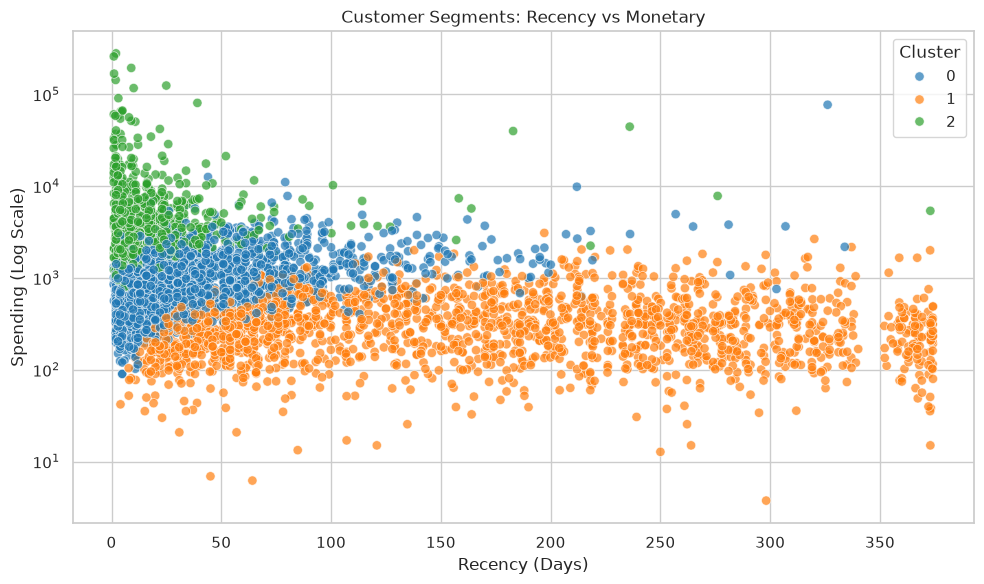

In [29]:
# Plot 1: Recency vs Frequency
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="tab10",
    s=45,
    alpha=0.7
)

plt.yscale("log")
plt.title("Customer Segments: Recency vs Frequency")
plt.xlabel("Recency (Days)")
plt.ylabel("Purchase Frequency (Log Scale)")

plt.tight_layout()
plt.show()

# Plot 2: Frequency vs Monetary
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    s=45,
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency (Log Scale)")
plt.ylabel("Total Spending (Log Scale)")

plt.tight_layout()
plt.show()

# Optional third plot: Recency vs Monetary
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    s=45,
    alpha=0.7
)

plt.yscale("log")
plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Spending (Log Scale)")

plt.tight_layout()
plt.show()

13. CLUSTER PROFILING


CLUSTER PROFILE
         CustomerCount  MeanRecency  MeanFrequency  MeanMonetary  MeanPurchaseValue  MeanObservedCLV  MedianMonetary  TotalRevenue  CustomerPercentage  RevenuePercentage
Cluster                                                                                                                                                                  
0                 1699        43.72           3.37       1257.30             453.71          1257.30          974.52    2136152.84               39.17              24.04
1                 1876       168.34           1.36        363.45             287.78           363.45          297.35     681838.13               43.25               7.67
2                  763        17.78          13.42       7954.41             656.65          7954.41         3717.35    6069217.92               17.59              68.29

MEAN RFM VALUES PER CLUSTER
         Recency  Frequency  Monetary
Cluster                              
0          43.72       3.37 

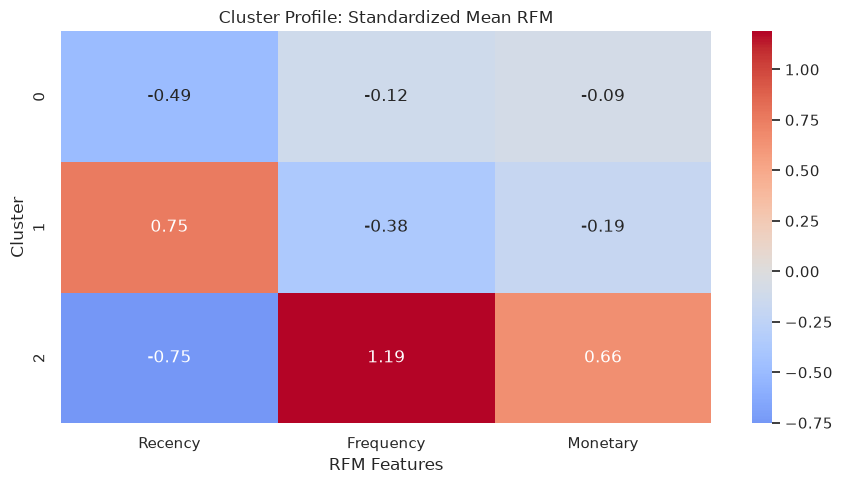

In [30]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        MeanRecency=("Recency", "mean"),
        MeanFrequency=("Frequency", "mean"),
        MeanMonetary=("Monetary", "mean"),
        MeanPurchaseValue=(
            "AveragePurchaseValue", "mean"
        ),
        MeanObservedCLV=(
            "ObservedCLVProxy", "mean"
        ),
        MedianMonetary=("Monetary", "median"),
        TotalRevenue=("Monetary", "sum")
    )
)

cluster_profile["CustomerPercentage"] = (
    cluster_profile["CustomerCount"]
    / len(rfm) * 100
)

cluster_profile["RevenuePercentage"] = (
    cluster_profile["TotalRevenue"]
    / rfm["Monetary"].sum() * 100
)

print("\nCLUSTER PROFILE")
print("=" * 60)

print(
    cluster_profile.round(2).to_string()
)

# Mean RFM metrics for each cluster
cluster_means = (
    rfm.groupby("Cluster")[features]
    .mean()
)

print("\nMEAN RFM VALUES PER CLUSTER")
print(cluster_means.round(2))

# Heatmap of relative cluster characteristics.
# Positive values are above overall average.
# Negative values are below overall average.

profile_scaled = (
    cluster_means
    - rfm[features].mean()
) / rfm[features].std(ddof=0)

plt.figure(figsize=(9, 5))

sns.heatmap(
    profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Cluster Profile: Standardized Mean RFM")
plt.xlabel("RFM Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

14. BAR CHART - CUSTOMERS PER CLUSTER

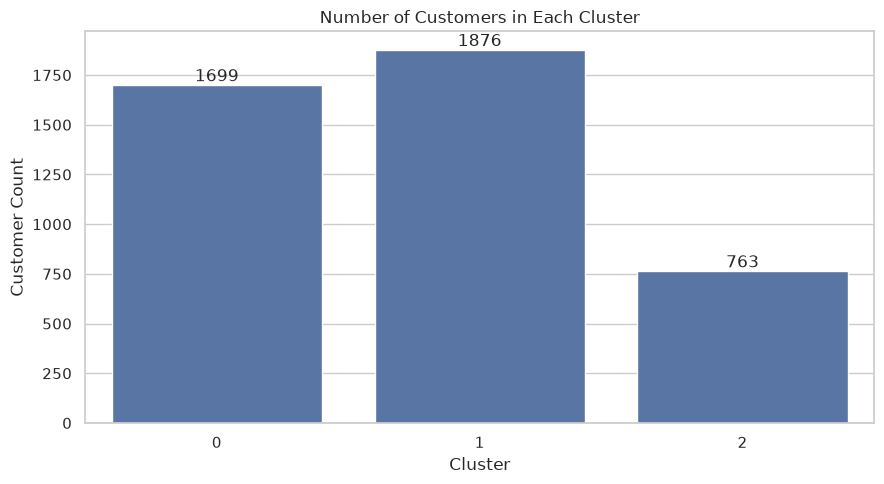

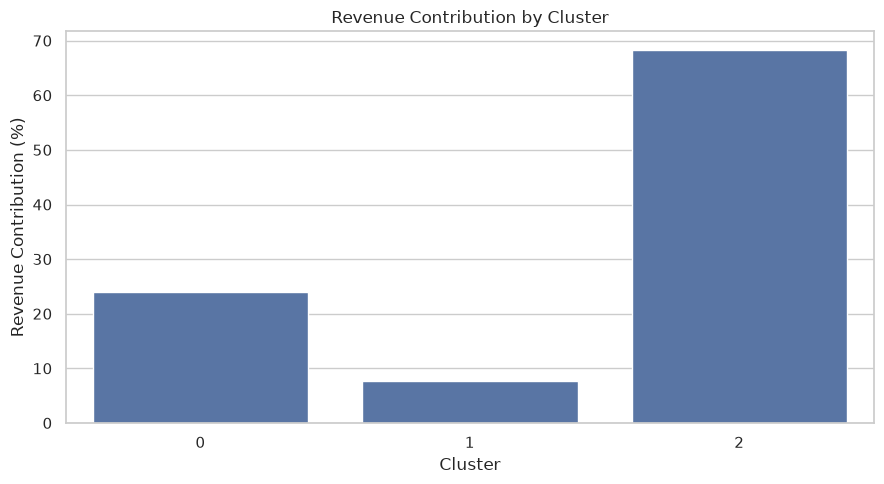

In [31]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=cluster_counts.index.astype(str),
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Customer Count")

for i, count in enumerate(cluster_counts.values):
    ax.text(
        i, count,
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Revenue contribution per cluster
revenue_by_cluster = (
    cluster_profile["RevenuePercentage"]
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=revenue_by_cluster.index.astype(str),
    y=revenue_by_cluster.values
)

plt.title("Revenue Contribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Revenue Contribution (%)")

plt.tight_layout()
plt.show()


15. CUSTOMER TYPES AND MARKETING RECOMMENDATIONS

In [32]:
# Compare clusters with the entire customer base.
# K-Means cluster numbers are arbitrary, so
# recommendations must be based on actual RFM values.

overall_recency = rfm["Recency"].median()
overall_frequency = rfm["Frequency"].median()
overall_monetary = rfm["Monetary"].median()

recommendations = []

for cluster_id, group in rfm.groupby("Cluster"):

    mean_recency = group["Recency"].mean()
    mean_frequency = group["Frequency"].mean()
    mean_monetary = group["Monetary"].mean()

    # Lower recency is better
    recent = mean_recency <= overall_recency

    # Higher frequency and spending are better
    frequent = mean_frequency >= overall_frequency
    high_spend = mean_monetary >= overall_monetary

    if recent and frequent and high_spend:

        segment = "Loyal High-Value Customers"

        action = (
            "Offer VIP benefits, early access, "
            "personalized rewards and referral incentives."
        )

    elif not recent and high_spend:

        segment = "At-Risk High-Value Customers"

        action = (
            "Launch win-back campaigns with personalized "
            "offers and reminders based on past purchases."
        )

    elif recent and not frequent:

        segment = "Recent / Occasional Customers"

        action = (
            "Provide first-repeat-purchase incentives, "
            "product recommendations and welcome campaigns."
        )

    elif recent and frequent:

        segment = "Active Repeat Customers"

        action = (
            "Promote bundles, loyalty points and "
            "cross-selling opportunities."
        )

    elif not recent and not frequent:

        segment = "Inactive / Low-Engagement Customers"

        action = (
            "Send limited-budget reactivation campaigns. "
            "Avoid expensive offers to unlikely responders."
        )

    else:

        segment = "Regular Customers"

        action = (
            "Use targeted recommendations, relevant "
            "discounts and engagement emails."
        )

    recommendations.append({
        "Cluster": cluster_id,
        "CustomerType": segment,
        "Customers": len(group),
        "MeanRecency": mean_recency,
        "MeanFrequency": mean_frequency,
        "MeanMonetary": mean_monetary,
        "MarketingRecommendation": action
    })

marketing_df = pd.DataFrame(recommendations)

print("\nSEGMENT DESCRIPTIONS AND MARKETING ACTIONS")
print("=" * 65)

for _, row in marketing_df.iterrows():

    print(f"\nCluster {int(row['Cluster'])}")

    print(
        "Customer type:",
        row["CustomerType"]
    )

    print(
        "Number of customers:",
        int(row["Customers"])
    )

    print(
        "Average recency:",
        round(row["MeanRecency"], 2),
        "days"
    )

    print(
        "Average purchase frequency:",
        round(row["MeanFrequency"], 2)
    )

    print(
        "Average total spending:",
        round(row["MeanMonetary"], 2)
    )

    print(
        "Recommended marketing strategy:",
        row["MarketingRecommendation"]
    )



SEGMENT DESCRIPTIONS AND MARKETING ACTIONS

Cluster 0
Customer type: Loyal High-Value Customers
Number of customers: 1699
Average recency: 43.72 days
Average purchase frequency: 3.37
Average total spending: 1257.3
Recommended marketing strategy: Offer VIP benefits, early access, personalized rewards and referral incentives.

Cluster 1
Customer type: Inactive / Low-Engagement Customers
Number of customers: 1876
Average recency: 168.34 days
Average purchase frequency: 1.36
Average total spending: 363.45
Recommended marketing strategy: Send limited-budget reactivation campaigns. Avoid expensive offers to unlikely responders.

Cluster 2
Customer type: Loyal High-Value Customers
Number of customers: 763
Average recency: 17.78 days
Average purchase frequency: 13.42
Average total spending: 7954.41
Recommended marketing strategy: Offer VIP benefits, early access, personalized rewards and referral incentives.


16. CUSTOMER SEGMENTATION SUMMARY

In [33]:
final_summary = cluster_profile.reset_index().merge(
    marketing_df[
        [
            "Cluster",
            "CustomerType",
            "MarketingRecommendation"
        ]
    ],
    on="Cluster"
)

print("\nFINAL SEGMENT SUMMARY")
print(
    final_summary.round(2).to_string(
        index=False
    )
)



FINAL SEGMENT SUMMARY
 Cluster  CustomerCount  MeanRecency  MeanFrequency  MeanMonetary  MeanPurchaseValue  MeanObservedCLV  MedianMonetary  TotalRevenue  CustomerPercentage  RevenuePercentage                        CustomerType                                                                    MarketingRecommendation
       0           1699        43.72           3.37       1257.30             453.71          1257.30          974.52    2136152.84               39.17              24.04          Loyal High-Value Customers            Offer VIP benefits, early access, personalized rewards and referral incentives.
       1           1876       168.34           1.36        363.45             287.78           363.45          297.35     681838.13               43.25               7.67 Inactive / Low-Engagement Customers Send limited-budget reactivation campaigns. Avoid expensive offers to unlikely responders.
       2            763        17.78          13.42       7954.41             656.6

17. SAVE OUTPUT FILES

In [34]:
# Individual customer RFM values and cluster labels
rfm.to_csv(
    "customer_rfm_clusters.csv",
    index=False
)

# Cluster statistics and segment recommendations
final_summary.to_csv(
    "customer_segment_summary.csv",
    index=False
)

# Cleaned transaction-level dataset
data.to_csv(
    "cleaned_ecommerce_data.csv",
    index=False
)

print("\nFiles saved:")
print("1. customer_rfm_clusters.csv")
print("2. customer_segment_summary.csv")
print("3. cleaned_ecommerce_data.csv")


Files saved:
1. customer_rfm_clusters.csv
2. customer_segment_summary.csv
3. cleaned_ecommerce_data.csv


18. FINAL PROJECT CONCLUSION

In [35]:
print("\nPROJECT CONCLUSION")
print("=" * 65)

print(
    "Total customers analysed:",
    len(rfm)
)

print(
    "Number of segments identified:",
    optimal_k
)

print(
    "Features used:",
    ", ".join(features)
)

print(
    "Clustering algorithm:",
    "K-Means"
)

print(
    "Scaling method:",
    "StandardScaler after log1p transformation"
)

print(
    "\nCustomer segmentation separates shoppers "
    "by their recent activity, order frequency "
    "and total purchase value."
)

print(
    "The resulting groups help create marketing "
    "strategies tailored to each segment."
)

print(
    "\nImportant limitation: Results describe "
    "historical transactions. Future customer "
    "lifetime value has not been predicted."
)


PROJECT CONCLUSION
Total customers analysed: 4338
Number of segments identified: 3
Features used: Recency, Frequency, Monetary
Clustering algorithm: K-Means
Scaling method: StandardScaler after log1p transformation

Customer segmentation separates shoppers by their recent activity, order frequency and total purchase value.
The resulting groups help create marketing strategies tailored to each segment.

Important limitation: Results describe historical transactions. Future customer lifetime value has not been predicted.
